In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [ ]:
df = pd.read_csv('/content/austin_weather.csv')
df.head()

,STATION,NAME,DATE,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,...,MLY-TMIN-AVGNDS-LSTH060,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV
0,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",1,190,103,50,35,18,1,-7777,...,302,310,36.3,298,570,839,967,997,1000,2.9
1,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",2,228,132,68,49,29,3,1,...,264,280,39.4,103,327,614,867,973,999,3.2
2,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",3,446,306,185,146,98,13,6,...,270,308,46.6,10,73,242,494,761,928,3.6
3,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",4,668,519,373,318,240,53,32,...,193,287,54.7,0,0,0,48,189,453,4.1
4,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",5,936,781,626,564,471,181,134,...,89,250,63.7,0,0,0,0,0,0,2.5


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 67 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   STATION                  12 non-null     object 
 1   NAME                     12 non-null     object 
 2   DATE                     12 non-null     int64  
 3   MLY-CLDD-BASE45          12 non-null     int64  
 4   MLY-CLDD-BASE50          12 non-null     int64  
 5   MLY-CLDD-BASE55          12 non-null     int64  
 6   MLY-CLDD-BASE57          12 non-null     int64  
 7   MLY-CLDD-BASE60          12 non-null     int64  
 8   MLY-CLDD-BASE70          12 non-null     int64  
 9   MLY-CLDD-BASE72          12 non-null     int64  
 10  MLY-CLDD-NORMAL          12 non-null     int64  
 11  MLY-DUTR-NORMAL          12 non-null     float64
 12  MLY-DUTR-STDDEV          12 non-null     float64
 13  MLY-GRDD-BASE40          12 non-null     int64  
 14  MLY-GRDD-BASE45          12 

,DATE,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,MLY-DUTR-NORMAL,...,MLY-TMIN-AVGNDS-LSTH060,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.00000,12.000000,12.00000,12.000000,...,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,6.500000,690.833333,556.583333,434.333333,388.916667,325.000000,147.25000,-529.750000,229.25000,24.900000,...,162.500000,240.333333,54.791667,54.916667,126.250000,224.250000,322.666667,402.166667,467.666667,2.833333
std,3.605551,387.016052,363.726285,327.724478,310.458446,281.726495,167.11081,2286.429099,227.14878,1.306626,...,123.338042,83.584833,13.549402,106.105829,212.561488,328.414684,410.183846,454.950713,471.603326,0.950917
min,1.000000,190.000000,103.000000,50.000000,35.000000,18.000000,1.00000,-7777.000000,5.00000,22.300000,...,0.000000,83.000000,36.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.300000
25%,3.750000,366.000000,243.750000,146.000000,114.250000,75.500000,9.75000,4.750000,31.25000,24.550000,...,44.000000,209.000000,43.975000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.350000
50%,6.500000,706.500000,555.000000,405.500000,348.500000,267.500000,68.00000,44.000000,152.50000,25.150000,...,196.000000,282.000000,55.300000,0.000000,0.000000,1.500000,36.500000,142.500000,358.500000,2.900000
75%,9.250000,1009.000000,859.000000,709.000000,649.000000,559.750000,267.25000,212.750000,411.25000,25.800000,...,269.250000,299.750000,66.450000,33.250000,136.500000,335.000000,614.250000,857.500000,976.500000,3.625000
max,12.000000,1199.000000,1044.000000,889.000000,827.000000,735.000000,425.00000,363.000000,580.00000,26.400000,...,302.000000,310.000000,71.700000,298.000000,570.000000,839.000000,967.000000,997.000000,1000.000000,4.100000


In [1]:
# data cleaning
df.drop(['DATE'], axis=1, inplace=True)

NameError: name 'df' is not defined

In [ ]:
# Replace invalid values
df.replace("T", 0.0, inplace=True)
df.replace("-", np.nan, inplace=True)

In [ ]:
df = df.apply(pd.to_numeric, errors='coerce')

In [ ]:
df.fillna(df.mean(), inplace=True)

In [ ]:
# Define Features & Target

X = df.drop('MLY-PRCP-NORMAL', axis=1)
y = df['MLY-PRCP-NORMAL']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
model = LinearRegression()
# Drop columns that contain NaN values from X_train and X_test
X_train = X_train.drop(['STATION', 'NAME'], axis=1)
X_test = X_test.drop(['STATION', 'NAME'], axis=1)
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 16.166967461474993
R2 Score: -1065.9162726077097


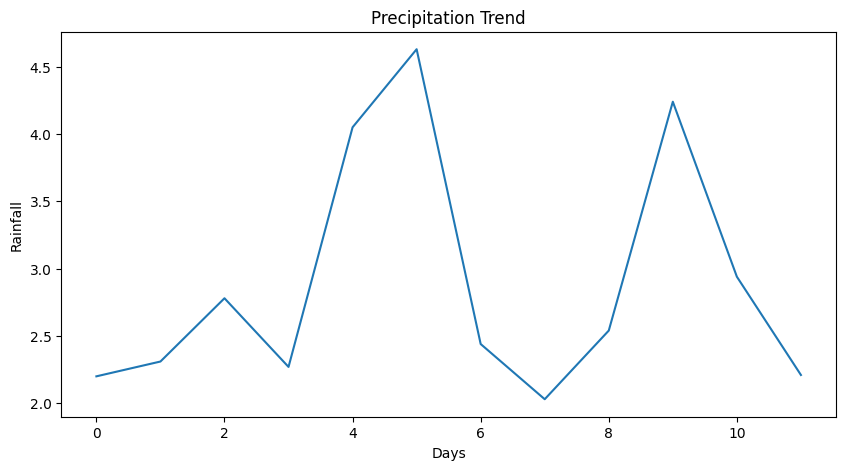

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(y.values)
plt.title("Precipitation Trend")
plt.xlabel("Days")
plt.ylabel("Rainfall")
plt.show()

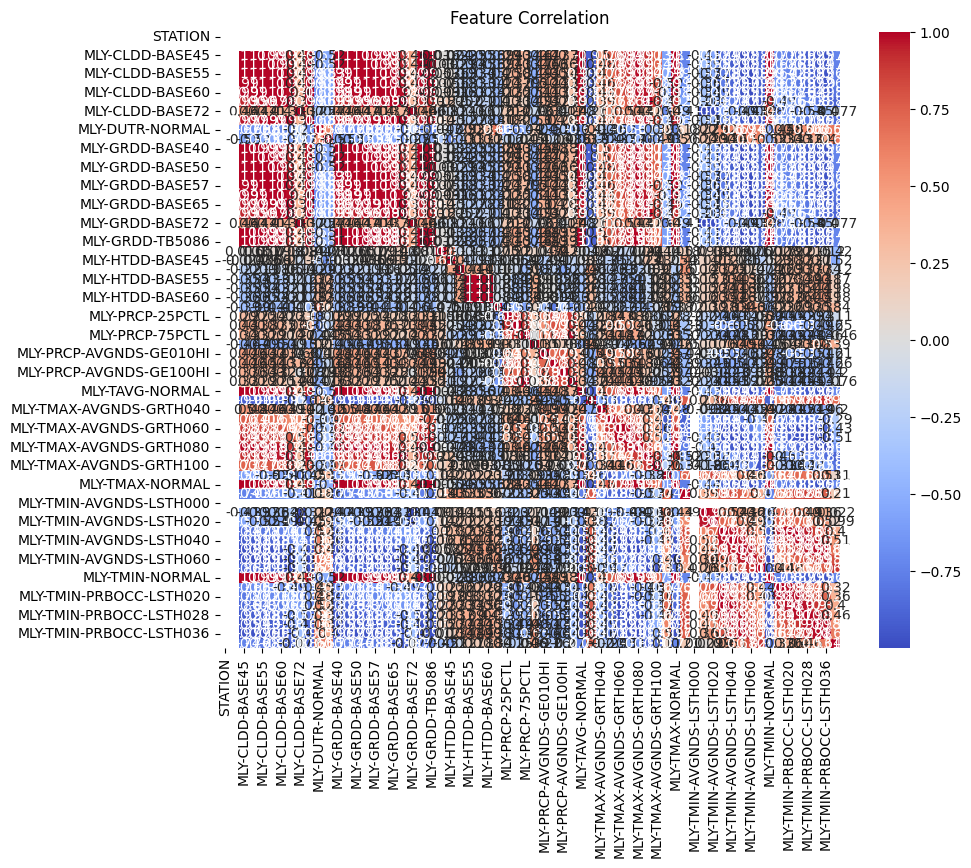

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

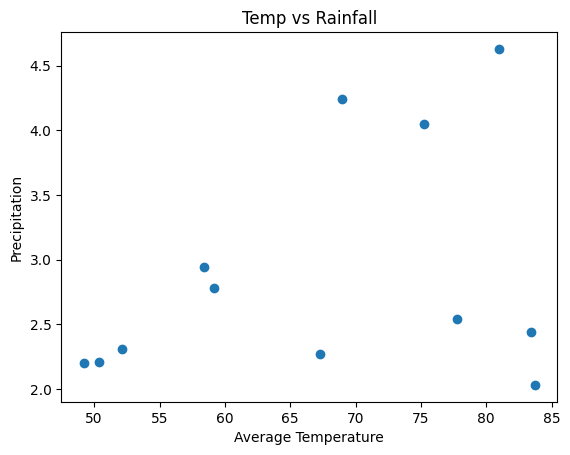

In [ ]:
plt.scatter(df['MLY-TAVG-NORMAL'], df['MLY-PRCP-NORMAL'])
plt.xlabel("Average Temperature")
plt.ylabel("Precipitation")
plt.title("Temp vs Rainfall")
plt.show()